# Introducción práctica a las Liquid Time-Constant Networks

Cuaderno complementario del artículo [*Liquid Time-Constant Networks: de las ecuaciones diferenciales a una implementación moderna*](https://laverde97.github.io/latent-frontiers/posts/liquid-time-constant-networks/) del blog *Latent Frontiers* (Juan Sebastián Laverde Chunza).

[Abrir en Google Colab](https://colab.research.google.com/github/Laverde97/latent-frontiers/blob/main/posts/liquid-time-constant-networks/analysis/ltc_intro.ipynb)

**Qué es:** una demostración educativa que implementa la Ec. (3) del paper de Hasani et al. (AAAI 2021) y entrena una pequeña red LTC sobre **datos sintéticos**.

**Qué no es:** una reproducción de los experimentos del paper. No usa sus datasets, ni su parametrización por sinapsis, ni compara con sus tablas.

**Requisitos:** CPU (no hace falta GPU), Python ≥ 3.10, `torch` ≥ 2.2, `numpy` y `matplotlib`. Probado con Python 3.14, PyTorch 2.14.1 (CPU), NumPy 2.5.3 y Matplotlib 3.11.2. Tarda menos de un minuto.

Contenido:

1. Una actualización a mano (Ec. 3).
2. La celda LTC en PyTorch.
3. Datos sintéticos: una tarea que necesita memoria.
4. Modelo, formas de los tensores, pérdida y optimizador.
5. Entrenamiento con BPTT.
6. Predicciones en secuencias no vistas.
7. La constante de tiempo efectiva a lo largo de una secuencia.

In [1]:
# En Google Colab, torch, numpy y matplotlib ya están instalados.
# En otro entorno:  pip install torch numpy matplotlib
import math

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)

print("torch", torch.__version__, "| numpy", np.__version__)

torch 2.14.1+cpu | numpy 2.5.3


## 1. Una actualización a mano

La Ec. (3) del paper avanza el estado de una neurona un paso $\Delta t$:

$$
x(t+\Delta t)=\frac{x(t)+\Delta t\,fA}{1+\Delta t\left(\frac{1}{\tau}+f\right)}
$$

Con los valores hipotéticos del artículo ($\tau = 2$, $f = 0{,}5$, $A = 1$, $\Delta t = 1$, $x(0) = 0$) el primer paso da $0{,}5 / 2 = 0{,}25$ y la constante de tiempo efectiva es $\tau_{sys} = 2/(1 + 2 \cdot 0{,}5) = 1$. Aquí $f$ se mantiene fija; en la red real cambia en cada paso.

In [2]:
def tau_sys(tau, f):
    """Constante de tiempo efectiva: τ_sys = τ / (1 + τ f)."""
    return tau / (1 + tau * f)


def fused_step(x, f, tau, A, dt):
    """Un paso de la Ec. (3) para una neurona, con f fija durante el paso."""
    numerator = x + dt * f * A                # estado actual + empuje hacia A
    denominator = 1 + dt * (1 / tau + f)      # parte implícita: fuga + modulación de f
    return numerator / denominator


tau, f, A, dt = 2.0, 0.5, 1.0, 1.0
print("tau_sys =", tau_sys(tau, f))
x = 0.0
for step in range(1, 4):
    x = fused_step(x, f, tau, A, dt)
    print(f"paso {step}: x = {x:.4f}")

tau_sys = 1.0
paso 1: x = 0.2500
paso 2: x = 0.3750
paso 3: x = 0.4375


## 2. La celda LTC en PyTorch

El código siguiente es una **copia literal** de `analysis/ltc_manual.py`, el mismo que se comenta en el artículo:

- `LTCCell.fused_step` es la Ec. (3) vectorizada sobre el lote y las neuronas.
- `LTCCell.forward` repite ese paso `unfolds` = $L$ veces por cada observación (Algorithm 1).
- `LTCNetwork.forward` recorre la secuencia, conserva el estado oculto de un instante al siguiente y aplica una capa lineal de salida (Algorithm 2).

In [3]:
class LTCCell(nn.Module):
    """Una celda LTC: avanza el estado oculto un paso de entrada (L FusedSteps)."""

    def __init__(self, input_size, hidden_size, unfolds=6, dt=1.0 / 6.0, activation="tanh"):
        super().__init__()
        self.input_size = input_size    # M: dimensión de la entrada I(t)
        self.hidden_size = hidden_size  # N: número de neuronas
        self.unfolds = unfolds          # L: pasos del solver por cada entrada
        self.dt = dt                    # Δt: tamaño del paso del solver
        self.activation = {"tanh": torch.tanh, "sigmoid": torch.sigmoid}[activation]

        bound = hidden_size ** -0.5
        # θ = {γ, γ_r, μ, τ} y el vector A, como en el Algorithm 1
        self.input_weights = nn.Parameter(torch.empty(input_size, hidden_size).uniform_(-bound, bound))       # γ   (M × N)
        self.recurrent_weights = nn.Parameter(torch.empty(hidden_size, hidden_size).uniform_(-bound, bound))  # γ_r (N × N)
        self.bias = nn.Parameter(torch.zeros(hidden_size))                                                    # μ   (N)
        self.log_tau = nn.Parameter(torch.zeros(hidden_size))                                                 # τ = exp(log_tau) > 0
        self.A = nn.Parameter(torch.empty(hidden_size).uniform_(-1.0, 1.0))                                   # A   (N)

    @property
    def tau(self):
        return torch.exp(self.log_tau)

    def f(self, x, input_t):
        """f(x(t), I(t), t, θ) = activación(γ_r x + γ I + μ).   Salida: (batch, N)."""
        return self.activation(x @ self.recurrent_weights + input_t @ self.input_weights + self.bias)

    def fused_step(self, x, input_t):
        """Ec. (3): un paso del Fused ODE Solver.   x: (batch, N), input_t: (batch, M)."""
        f_val = self.f(x, input_t)
        numerator = x + self.dt * f_val * self.A
        denominator = 1.0 + self.dt * (1.0 / self.tau + f_val)
        x_next = numerator / denominator
        return x_next

    def tau_sys(self, x, input_t):
        """Constante de tiempo efectiva: τ_sys = τ / (1 + τ f)."""
        return self.tau / (1.0 + self.tau * self.f(x, input_t))

    def forward(self, input_t, x):
        for _ in range(self.unfolds):  # bucle "for i = 1 ... L" del Algorithm 1
            x = self.fused_step(x, input_t)
        return x


class LTCNetwork(nn.Module):
    """Celda LTC desenrollada en el tiempo + capa lineal de salida (Algorithm 2)."""

    def __init__(self, input_size, hidden_size, output_size, unfolds=6, dt=1.0 / 6.0, activation="tanh"):
        super().__init__()
        self.cell = LTCCell(input_size, hidden_size, unfolds, dt, activation)
        self.readout = nn.Linear(hidden_size, output_size)  # W_out, b_out

    def forward(self, sequence, initial_state=None):
        # sequence: (batch, T, M)
        batch_size, seq_len, _ = sequence.shape
        x = initial_state
        if x is None:
            x = sequence.new_zeros(batch_size, self.cell.hidden_size)  # x(0)

        outputs = []
        for t in range(seq_len):               # bucle "for j = 1 ... T" del Algorithm 2
            input_t = sequence[:, t, :]        # I(t): (batch, M)
            x = self.cell(input_t, x)          # x(t + Δt): (batch, N)
            outputs.append(self.readout(x))    # ŷ(t) = W_out x + b_out
        return torch.stack(outputs, dim=1), x  # (batch, T, salida), (batch, N)


## 3. Datos sintéticos: una tarea que necesita memoria

La entrada $u(t)$ es una señal que salta entre niveles aleatorios cada pocos pasos, con algo de ruido. El objetivo $y(t)$ es una versión **suavizada** de esa señal: un filtro de primer orden con constante de tiempo de 3 pasos,

$$
y(t) = y(t-1) + \alpha\,\big(u(t) - y(t-1)\big), \qquad \alpha = 1 - e^{-1/3}.
$$

Para predecir $y(t)$ no basta con mirar $u(t)$: hay que recordar los valores anteriores. Es una tarea de juguete elegida para este cuaderno, no un dataset del paper.

entrenamiento: (32, 64, 1) | prueba: (8, 64, 1)


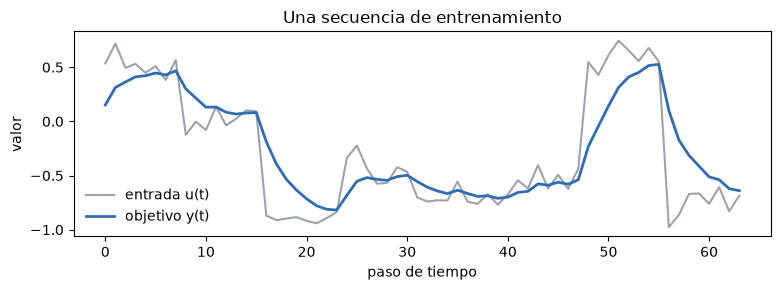

In [4]:
def make_data(n_sequences, length, generator):
    """Entrada escalonada con ruido y su versión filtrada (constante de tiempo de 3 pasos)."""
    alpha = 1 - math.exp(-1 / 3)
    inputs = torch.zeros(n_sequences, length, 1)
    targets = torch.zeros(n_sequences, length, 1)
    for i in range(n_sequences):
        level, y = 0.0, 0.0
        for t in range(length):
            if t % 8 == 0:                                   # nuevo nivel cada 8 pasos
                level = float(torch.empty(1).uniform_(-1, 1, generator=generator))
            u = level + 0.1 * float(torch.randn(1, generator=generator))
            y = y + alpha * (u - y)
            inputs[i, t, 0], targets[i, t, 0] = u, y
    return inputs, targets


train_x, train_y = make_data(32, 64, torch.Generator().manual_seed(1))
test_x, test_y = make_data(8, 64, torch.Generator().manual_seed(2))   # secuencias no vistas
print("entrenamiento:", tuple(train_x.shape), "| prueba:", tuple(test_x.shape))

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(train_x[0, :, 0], color="#9CA3AF", label="entrada u(t)")
ax.plot(train_y[0, :, 0], color="#2E6DB4", linewidth=2, label="objetivo y(t)")
ax.set_xlabel("paso de tiempo"); ax.set_ylabel("valor"); ax.legend(frameon=False)
ax.set_title("Una secuencia de entrenamiento")
plt.tight_layout(); plt.show()

## 4. Modelo, formas, pérdida y optimizador

Las formas siguen la convención `(batch_size, sequence_length, input_size)`:

- `batch_size`: cuántas secuencias se procesan a la vez (32 en entrenamiento).
- `sequence_length`: cuántos instantes tiene cada secuencia (64).
- `input_size`: cuántos valores se observan en cada instante (1).

El estado oculto tiene forma `(batch_size, hidden_size)`. Se usa la activación **sigmoide**, de modo que $f \in (0, 1)$: es el caso que cubren los Teoremas 1 y 2. El ejemplo del paper usa $\tanh$, que puede dar $f < 0$.

In [5]:
torch.manual_seed(SEED)
model = LTCNetwork(input_size=1, hidden_size=16, output_size=1, activation="sigmoid")
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, betas=(0.9, 0.999), eps=1e-8)

outputs, last_state = model(train_x)
print("salidas:", tuple(outputs.shape), "| estado final:", tuple(last_state.shape))
for name, parameter in model.named_parameters():
    print(f"{name:24s} {str(tuple(parameter.shape)):10s} entrenable={parameter.requires_grad}")
print("parámetros entrenables:", sum(p.numel() for p in model.parameters()))

salidas: (32, 64, 1) | estado final: (32, 16)
cell.input_weights       (1, 16)    entrenable=True
cell.recurrent_weights   (16, 16)   entrenable=True
cell.bias                (16,)      entrenable=True
cell.log_tau             (16,)      entrenable=True
cell.A                   (16,)      entrenable=True
readout.weight           (1, 16)    entrenable=True
readout.bias             (1,)       entrenable=True
parámetros entrenables: 337


## 5. Entrenamiento con BPTT

Cada iteración desenrolla la secuencia ($T \times L$ pasos fusionados), calcula la pérdida sobre todos los instantes y llama a `loss.backward()`: la diferenciación automática recorre ese grafo hacia atrás, que es exactamente *backpropagation through time*. `optimizer.step()` actualiza los parámetros (Adam, como en los experimentos del paper; el Algorithm 2 escribe SGD).

MSE de entrenamiento: inicial 0.2214 → final 0.0009


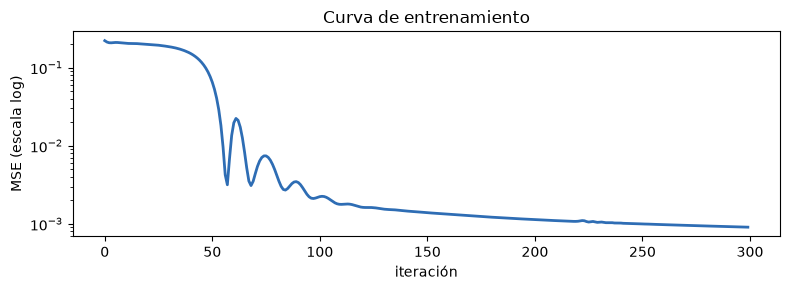

In [6]:
losses = []
for step in range(300):
    optimizer.zero_grad()
    outputs, _ = model(train_x)             # forward: T × L pasos de la Ec. (3)
    loss = criterion(outputs, train_y)      # pérdida sobre todos los instantes
    loss.backward()                         # BPTT a través del grafo desenrollado
    optimizer.step()
    losses.append(loss.item())

print(f"MSE de entrenamiento: inicial {losses[0]:.4f} → final {losses[-1]:.4f}")
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(losses, color="#2E6DB4", linewidth=2)
ax.set_yscale("log"); ax.set_xlabel("iteración"); ax.set_ylabel("MSE (escala log)")
ax.set_title("Curva de entrenamiento")
plt.tight_layout(); plt.show()

## 6. Predicciones en secuencias no vistas

Se evalúa en 8 secuencias generadas con otra semilla. Como referencia se incluye una predicción **sin memoria** que copia la entrada actual ($\hat{y}(t) = u(t)$): si el modelo no superara esa referencia, no estaría usando el pasado.

MSE en prueba — LTC: 0.0008 | copiar la entrada: 0.0999


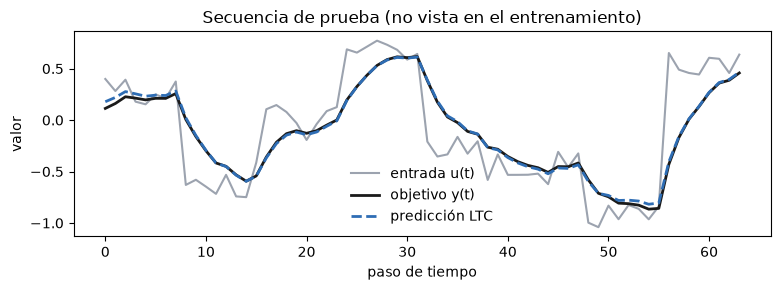

In [7]:
model.eval()
with torch.no_grad():
    predictions, _ = model(test_x)
mse_model = criterion(predictions, test_y).item()
mse_copy = criterion(test_x, test_y).item()
print(f"MSE en prueba — LTC: {mse_model:.4f} | copiar la entrada: {mse_copy:.4f}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(test_x[0, :, 0], color="#9CA3AF", label="entrada u(t)")
ax.plot(test_y[0, :, 0], color="#1A1A1A", linewidth=2, label="objetivo y(t)")
ax.plot(predictions[0, :, 0], color="#2E6DB4", linewidth=2, linestyle="--", label="predicción LTC")
ax.set_xlabel("paso de tiempo"); ax.set_ylabel("valor"); ax.legend(frameon=False)
ax.set_title("Secuencia de prueba (no vista en el entrenamiento)")
plt.tight_layout(); plt.show()

## 7. La constante de tiempo efectiva a lo largo de una secuencia

Para cada instante se calcula $\tau_{sys} = \tau / (1 + \tau f)$ en cada neurona, con el estado y la entrada de ese instante. Con la sigmoide, el Teorema 1 garantiza $\tau/(1+\tau) \le \tau_{sys} \le \tau$ (aquí $W_i = 1$). Las líneas muestran cómo cambia $\tau_{sys}$ con los saltos de la entrada: es lo que significa "constante de tiempo líquida".

τ_sys dentro de las cotas del Teorema 1 en todos los instantes: True


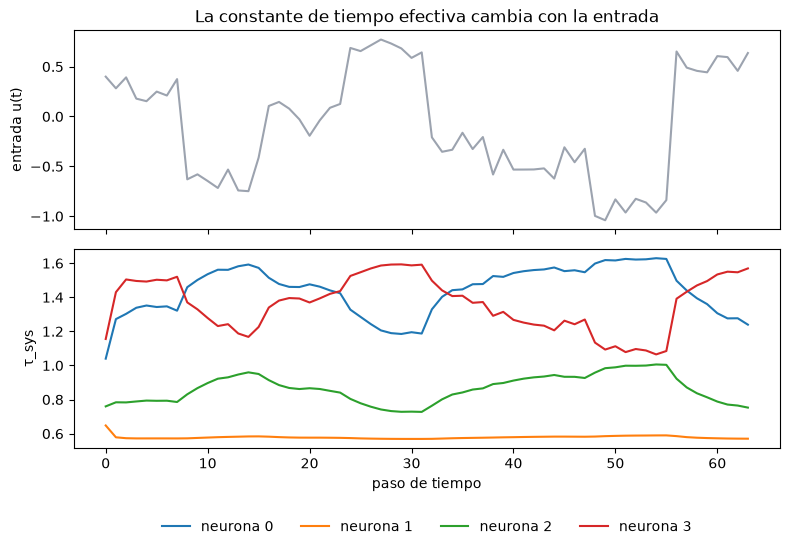

In [8]:
cell = model.cell
sequence = test_x[:1]                                   # (1, T, 1)
x = torch.zeros(1, cell.hidden_size)
history = []
with torch.no_grad():
    for t in range(sequence.shape[1]):
        input_t = sequence[:, t, :]
        history.append(cell.tau_sys(x, input_t)[0])    # τ_sys de cada neurona en este instante
        x = cell(input_t, x)
history = torch.stack(history)                          # (T, N)

tau = cell.tau.detach()
lower, upper = tau / (1 + tau), tau
inside = bool(((history >= lower - 1e-6) & (history <= upper + 1e-6)).all())
print("τ_sys dentro de las cotas del Teorema 1 en todos los instantes:", inside)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5.6), sharex=True)
ax1.plot(sequence[0, :, 0], color="#9CA3AF"); ax1.set_ylabel("entrada u(t)")
for i in range(4):
    ax2.plot(history[:, i], linewidth=1.5, label=f"neurona {i}")
ax2.set_xlabel("paso de tiempo"); ax2.set_ylabel("τ_sys")
ax2.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.3))
ax1.set_title("La constante de tiempo efectiva cambia con la entrada")
plt.tight_layout(); plt.show()

## Qué muestra este cuaderno y qué no

**Muestra** que la Ec. (3) se implementa en pocas líneas, que la red se entrena con BPTT mediante `loss.backward()`, que en esta tarea de juguete aprende a usar el pasado (supera a la predicción sin memoria en secuencias no vistas) y que $\tau_{sys}$ varía con la entrada sin salir de las cotas del Teorema 1 cuando $f$ es una sigmoide.

**No muestra** nada sobre el rendimiento de las LTC en los problemas del paper ni frente a otras arquitecturas: no se ha comparado con LSTM, CT-RNN ni Neural ODE, los datos son sintéticos y se ha usado una sola semilla. Para la discusión de los resultados publicados, ver la sección de experimentos del artículo.